# Finanzkennzahlen der Big-Tech-Unternehmen im Vergleich
**Datenprojekt im Modul Business Analytics** · DHBW Bad Mergentheim, Digital Business Management · Dozent: Thomas Burghardt

**Studenten:** Kris Lämmermann, Vincent Eckart

**Untersuchte Unternehmen:** Apple (AAPL), Microsoft (MSFT), Amazon (AMZN), Tesla (TSLA), Alphabet (GOOGL)

Das Projekt wurde mit der Methode **Vibe Coding** umgesetzt (Dokumentation: `VIBE_CODING.md` im Repository). Das Notebook folgt den **fünf Phasen einer statistischen Untersuchung**:

| Phase | Inhalt in diesem Notebook |
|---|---|
| 1. Vorbereitung | Zielstellung, Abgrenzung, Forschungsfragen, Hypothesen |
| 2. Datenerhebung | Sekundärdaten laden, Datenbeschreibung, FAIR-Prinzipien |
| 3. Aufbereitung und Darstellung | Qualitätsprüfung, Bereinigung, Umformung, Häufigkeitsverteilungen |
| 4. Datenauswertung und -analyse | Forschungsfragen 1 bis 5 mit statistischen Verfahren |
| 5. Ergebnispräsentation | Zusammenfassung, Hypothesenprüfung, Limitationen |

Alle Zahlen in diesem Notebook werden direkt aus der CSV-Datei berechnet. Beträge werden in **Mrd. USD** angegeben.

---
## Phase 1: Vorbereitung

### 1.1 Zielstellung
Ziel ist es, die Geschäftsentwicklung von fünf börsennotierten Technologieunternehmen anhand ihrer Finanzkennzahlen (Gewinn- und Verlustrechnung) zu analysieren und zu vergleichen: Umsatz, Gewinn, Profitabilität, Steuerbelastung, Gewinn je Aktie und Sondereffekte.

### 1.2 Abgrenzung des Untersuchungsgegenstandes
- **Unternehmen:** AAPL, MSFT, AMZN, TSLA, GOOGL (Teilmenge der S&P-500-Unternehmen im Datensatz). Bei den Forschungsfragen 2 und 3 wird ergänzend der gesamte Datensatz als Vergleich herangezogen.
- **Zeitraum:** die im Datensatz enthaltenen Geschäftsjahre (je Unternehmen 4 auswertbare Jahre, siehe Phase 3).
- **Kennzahlen:** Total Revenue, Operating Revenue, Net Income, Tax Rate For Calcs, Diluted EPS, Tax Effect Of Unusual Items (zur Erklärung zusätzlich Total Unusual Items, Normalized Income, Diluted Average Shares).

### 1.3 Forschungsfragen

| Nr. | Forschungsfrage | Verfahren |
|---|---|---|
| FF1 | Wie hat sich der durchschnittliche Total Revenue der fünf Unternehmen über die Perioden entwickelt? | Gruppierung nach Geschäftsjahr, Mittelwert, Liniendiagramm |
| FF2 | Welches der fünf Unternehmen hat in der aktuellsten Periode den höchsten Net Income? | Filtern, Sortieren, Balkendiagramm |
| FF3 | Gibt es eine Korrelation zwischen Tax Rate For Calcs und der Nettogewinnmarge (Net Income / Total Revenue)? | Pivotieren, neues Feature, Pearson- und Spearman-Korrelation, Scatter-Plot mit Trendlinie |
| FF4 | Welches Unternehmen hat die höchste Volatilität beim Diluted EPS, und lässt sich diese durch Tax Effect Of Unusual Items erklären? | Standardabweichung, Variationskoeffizient, Vergleich mit Sondereffekten |
| FF5 | Lassen sich mit Z-Score oder rollierendem Durchschnitt Anomalien im Operating Revenue erkennen? | Zeitreihenanalyse, rollierender Durchschnitt, Z-Score, farbliche Markierung |

### 1.4 Hypothesen (Erwartungen vor der Auswertung)
- **H1:** Der durchschnittliche Umsatz der fünf Unternehmen steigt von Jahr zu Jahr.
- **H2:** Das umsatzstärkste Unternehmen erzielt auch den höchsten Nettogewinn.
- **H3:** Eine höhere Steuerquote geht mit einer niedrigeren Nettogewinnmarge einher (negative Korrelation).
- **H4:** Unternehmen mit hoher EPS-Volatilität weisen auch hohe Sondereffekte auf.
- **H5:** In den Umsatzzeitreihen lassen sich einzelne Jahre statistisch als Auffälligkeiten identifizieren.

---
## Phase 2: Datenerhebung

### 2.1 Art der Erhebung
Es handelt sich um eine **Sekundärerhebung**: Die Daten wurden nicht selbst erhoben, sondern liegen als fertige CSV-Datei mit Finanzdaten der S&P-500-Unternehmen vor.

- **Datei:** `04_company_financials[1].csv`
- **Herkunft / Originalquelle:** Kaggle-Datensatz „S&P 500“ (Nutzer *sadiqguru*): https://www.kaggle.com/datasets/sadiqguru/s-and-p-500-stock-data-along-with-financials-and-news/data
- **Nutzung:** ausschließlich zu Lehrzwecken

### 2.2 Bibliotheken und Einstellungen

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

# Einheitliches, ruhiges Diagramm-Layout
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e3e2de",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "lines.linewidth": 2,
    "font.size": 10,
})

# Feste Farbe und Markerform je Unternehmen (Farbe folgt immer dem Unternehmen)
UNTERNEHMEN = ["AAPL", "MSFT", "AMZN", "TSLA", "GOOGL"]
FARBEN = {"AAPL": "#2a78d6", "MSFT": "#eb6834", "AMZN": "#1baf7a", "TSLA": "#eda100", "GOOGL": "#e87ba4"}
MARKER = {"AAPL": "o", "MSFT": "s", "AMZN": "^", "TSLA": "D", "GOOGL": "v"}
GRAU, DUNKEL, ROT = "#8a8984", "#0b0b0b", "#e34948"
MRD = 1e9  # Umrechnung USD -> Mrd. USD

### 2.3 Daten laden und erster Überblick
Die Datei liegt im **Long-Format** vor: Jede Zeile enthält genau einen Wert (`Value`) einer Kennzahl (`Item`) für ein Unternehmen (`Symbol`) zu einem Periodenende (`Period`).

In [2]:
# Mögliche Speicherorte der CSV im Repository
KANDIDATEN = ["04_company_financials[1].csv", "04_company_financials1.csv", "04_company_financials.csv",
              "data/04_company_financials1.csv", "data/04_company_financials.csv"]
DATEI = next((Path(p) for p in KANDIDATEN if Path(p).exists()), None)
if DATEI is None:
    raise FileNotFoundError("CSV-Datei nicht gefunden – bitte Pfad in KANDIDATEN anpassen.")

roh = pd.read_csv(DATEI, parse_dates=["Period"])

print(f"Datei:              {DATEI}")
print(f"Zeilen x Spalten:   {roh.shape[0]:,} x {roh.shape[1]}")
print(f"Unternehmen:        {roh['Symbol'].nunique()}")
print(f"Kennzahlen (Items): {roh['Item'].nunique()}")
print(f"Periodenenden:      {roh['Period'].min().date()} bis {roh['Period'].max().date()}")
print("\nDatentypen:")
print(roh.dtypes)
display(roh.head())

Datei:              04_company_financials[1].csv
Zeilen x Spalten:   114,528 x 4
Unternehmen:        509
Kennzahlen (Items): 84
Periodenenden:      2021-09-30 bis 2026-07-31

Datentypen:
Symbol               str
Item                 str
Period    datetime64[us]
Value            float64
dtype: object


,Symbol,Item,Period,Value
0,MMM,Tax Effect Of Unusual Items,2025-12-31,5.713743e+07
1,MMM,Tax Effect Of Unusual Items,2024-12-31,2.609371e+08
2,MMM,Tax Effect Of Unusual Items,2023-12-31,9.144000e+06
3,MMM,Tax Effect Of Unusual Items,2022-12-31,1.103850e+08
4,MMM,Tax Effect Of Unusual Items,2021-12-31,0.000000e+00


### 2.4 Datendokumentation (verwendete Variablen)

| Variable | Bedeutung | Einheit |
|---|---|---|
| `Symbol` | Börsenkürzel des Unternehmens | Text |
| `Item` | Name der Kennzahl | Text |
| `Period` | Ende des Geschäftsjahres | Datum |
| `Value` | Wert der Kennzahl | USD bzw. Quote |
| Total Revenue | Gesamtumsatz | USD |
| Operating Revenue | Umsatz aus der operativen Geschäftstätigkeit | USD |
| Net Income | Nettogewinn (Jahresüberschuss) | USD |
| Tax Rate For Calcs | Steuerquote, wie sie im Datensatz geliefert wird (Prüfung der Berechnung in Phase 3) | Anteil (0 bis 1) |
| Diluted EPS | verwässertes Ergebnis je Aktie | USD je Aktie |
| Tax Effect Of Unusual Items | Steuereffekt der Sondereffekte | USD |
| Total Unusual Items | Sondereffekte vor Steuern | USD |
| Normalized Income | um Sondereffekte bereinigter Gewinn | USD |
| Diluted Average Shares | durchschnittliche Anzahl verwässerter Aktien | Stück |

### 2.5 FAIR-Prinzipien
Die FAIR-Prinzipien beschreiben, wie Forschungsdaten auffindbar, zugänglich, interoperabel und wiederverwendbar sein sollen. Umsetzung in diesem Projekt:

| Prinzip | Bedeutung | Umsetzung im Projekt |
|---|---|---|
| **F**indable | Daten und Ergebnisse sind auffindbar | öffentliches GitHub-Repository mit README und eindeutigen Dateinamen |
| **A**ccessible | Daten sind zugänglich | CSV-Datei liegt im Repository, Code ist offen einsehbar |
| **I**nteroperable | offene, standardisierte Formate | CSV (offenes Textformat), Jupyter Notebook (`.ipynb`), Python mit Standardbibliotheken |
| **R**eusable | nachvollziehbar und wiederverwendbar | Bereinigungsschritte und Variablen dokumentiert, Analyse reproduzierbar (Notebook von oben nach unten ausführbar), Versionierung mit Git, Nutzungsbedingungen genannt |

---
## Phase 3: Aufbereitung und Darstellung

### 3.1 Qualitätsprüfung: fehlende Werte und Duplikate

In [3]:
print("Fehlende Werte je Spalte:")
print(roh.isna().sum())
print("\nDoppelte Einträge (Symbol, Item, Period):", roh.duplicated(["Symbol", "Item", "Period"]).sum())
print("\nAnzahl Perioden je Unternehmen:")
print(roh.groupby("Symbol")["Period"].nunique().value_counts().rename("Anzahl Unternehmen"))

Fehlende Werte je Spalte:
Symbol    0
Item      0
Period    0
Value     0
dtype: int64

Doppelte Einträge (Symbol, Item, Period): 0

Anzahl Perioden je Unternehmen:
Period
5    375
4    134
Name: Anzahl Unternehmen, dtype: int64


### 3.2 Umformung vom Long- ins Wide-Format
Für Berechnungen über mehrere Kennzahlen hinweg (z. B. Gewinnmarge = Net Income / Total Revenue) werden die Kennzahlen mit `pivot_table` zu Spalten umgeformt. Danach steht pro Unternehmen und Periode eine Zeile.

In [4]:
breit = roh.pivot_table(index=["Symbol", "Period"], columns="Item", values="Value").reset_index()
breit.columns.name = None
print(f"Wide-Format: {breit.shape[0]:,} Unternehmensjahre x {breit.shape[1]} Spalten")

Wide-Format: 2,411 Unternehmensjahre x 86 Spalten


### 3.3 Entdecktes Problem: Nullen als Platzhalter für fehlende Jahre
Formal gibt es keine fehlenden Werte (NaN). Bei der Sichtung fällt aber auf, dass einzelne Unternehmensjahre **ausschließlich Nullen** in den zentralen Kennzahlen enthalten. Ein Umsatz von 0 USD ist für ein S&P-500-Unternehmen nicht plausibel: Die Nullen stehen für **nicht gelieferte Daten**. Würde man sie mitrechnen, wären Mittelwerte, Standardabweichungen und Wachstumsraten verfälscht.

In [5]:
KENNZAHLEN = ["Total Revenue", "Operating Revenue", "Net Income", "Tax Rate For Calcs",
              "Diluted EPS", "Tax Effect Of Unusual Items"]

platzhalter = breit["Total Revenue"] <= 0
print("Betroffene Jahre bei den fünf untersuchten Unternehmen:")
display(breit.loc[platzhalter & breit["Symbol"].isin(UNTERNEHMEN), ["Symbol", "Period"] + KENNZAHLEN])

print(f"Unternehmensjahre mit Umsatz <= 0 im Gesamtdatensatz: {platzhalter.sum()} von {len(breit):,}")
print("Verteilung nach Jahr des Periodenendes:")
print(breit.loc[platzhalter, "Period"].dt.year.value_counts().sort_index())

Betroffene Jahre bei den fünf untersuchten Unternehmen:


,Symbol,Period,Total Revenue,Operating Revenue,Net Income,Tax Rate For Calcs,Diluted EPS,Tax Effect Of Unusual Items
4,AAPL,2021-09-30,0.0,0.0,0.0,0.0,0.0,0.0
2138,TSLA,2021-12-31,0.0,0.0,0.0,0.0,0.0,0.0


Unternehmensjahre mit Umsatz <= 0 im Gesamtdatensatz: 375 von 2,411
Verteilung nach Jahr des Periodenendes:
Period
2021    327
2022     47
2026      1
Name: count, dtype: int64


**Bereinigungsregel:** Unternehmensjahre mit `Total Revenue <= 0` werden als fehlend behandelt und entfernt.

Zusätzlich wird geprüft, ob Unternehmen **doppelt** enthalten sind. Manche Konzerne sind mit zwei Aktiengattungen im S&P 500 gelistet (z. B. GOOG und GOOGL für Alphabet). Erkennbar ist das daran, dass Umsatz und Gewinn in derselben Periode exakt identisch sind.

In [6]:
daten = breit.loc[~platzhalter].copy()
daten["GJ"] = daten["Period"].dt.year  # Geschäftsjahr = Kalenderjahr des Periodenendes

doppelt = daten.duplicated(subset=["Period", "Total Revenue", "Net Income"], keep=False)
gruppen = (daten.loc[doppelt].groupby(["Period", "Total Revenue", "Net Income"])["Symbol"]
           .apply(lambda s: " / ".join(sorted(s))))
print("Symbole mit identischen Finanzdaten (Doppellistungen):")
print(sorted(gruppen.unique()))

# Für Vergleiche über den Gesamtdatensatz wird je Doppellistung nur ein Symbol behalten
daten_sp = (daten.sort_values("Symbol")
                 .drop_duplicates(subset=["Period", "Total Revenue", "Net Income"], keep="last"))
print(f"\nBereinigter Gesamtdatensatz: {len(daten_sp):,} Unternehmensjahre, {daten_sp['Symbol'].nunique()} Unternehmen")

Symbole mit identischen Finanzdaten (Doppellistungen):
['FOX / FOXA', 'GOOG / GOOGL', 'NWS / NWSA']

Bereinigter Gesamtdatensatz: 2,024 Unternehmensjahre, 506 Unternehmen


### 3.4 Teilmenge der fünf Unternehmen und unterschiedliche Geschäftsjahre

In [7]:
big5 = daten[daten["Symbol"].isin(UNTERNEHMEN)].copy()

print("Auswertbare Geschäftsjahre je Unternehmen (1 = vorhanden):")
display(big5.pivot_table(index="Symbol", columns="GJ", values="Total Revenue", aggfunc="count")
            .reindex(UNTERNEHMEN).fillna(0).astype(int))

print("Geschäftsjahresende (Tag.Monat):", big5.groupby("Symbol")["Period"].max().dt.strftime("%d.%m.").to_dict())
print("Fehlende Werte in den benötigten Kennzahlen:", int(big5[KENNZAHLEN].isna().sum().sum()))
print("Operating Revenue identisch mit Total Revenue (alle 5 Unternehmen):",
      bool((big5["Operating Revenue"] == big5["Total Revenue"]).all()))

Auswertbare Geschäftsjahre je Unternehmen (1 = vorhanden):


GJ,2022,2023,2024,2025,2026
Symbol,,,,,
AAPL,1,1,1,1,0
MSFT,0,1,1,1,1
AMZN,1,1,1,1,0
TSLA,1,1,1,1,0
GOOGL,1,1,1,1,0


Geschäftsjahresende (Tag.Monat): {'AAPL': '30.09.', 'AMZN': '31.12.', 'GOOGL': '31.12.', 'MSFT': '30.06.', 'TSLA': '31.12.'}
Fehlende Werte in den benötigten Kennzahlen: 0
Operating Revenue identisch mit Total Revenue (alle 5 Unternehmen): True


**Konsequenzen für die Analyse:**
- Jedes Unternehmen hat nach der Bereinigung **4 auswertbare Geschäftsjahre**.
- Die Geschäftsjahre enden zu unterschiedlichen Zeitpunkten (Apple im September, Microsoft im Juni, die übrigen im Dezember). Gruppiert man stur nach dem Datum in `Period`, stünde pro Datum oft nur ein Unternehmen. Deshalb wird nach dem **Geschäftsjahr (GJ)** gruppiert, also dem Kalenderjahr des Periodenendes.
- Für alle fünf Unternehmen ist Operating Revenue gleich Total Revenue. FF1 und FF5 betrachten also dieselbe Umsatzgröße, einmal als Durchschnitt und einmal je Unternehmen als Zeitreihe.

### 3.5 Bereinigte Datenübersicht der fünf Unternehmen

In [8]:
uebersicht = big5[["Symbol", "GJ", "Period", "Total Revenue", "Net Income", "Diluted EPS", "Tax Rate For Calcs"]].copy()
uebersicht["Total Revenue"] = (uebersicht["Total Revenue"] / MRD).round(1)
uebersicht["Net Income"] = (uebersicht["Net Income"] / MRD).round(1)
uebersicht["Tax Rate For Calcs"] = (uebersicht["Tax Rate For Calcs"] * 100).round(1)
uebersicht["Period"] = uebersicht["Period"].dt.date
display(uebersicht.rename(columns={"Total Revenue": "Umsatz (Mrd. USD)", "Net Income": "Nettogewinn (Mrd. USD)",
                                   "Tax Rate For Calcs": "Steuerquote (%)"})
                  .set_index(["Symbol", "GJ"]))

Period  Umsatz (Mrd. USD)  Nettogewinn (Mrd. USD)  Diluted EPS  Steuerquote (%)
Symbol GJ                                                                                       
AAPL   2022  2022-09-30              394.3                    99.8         6.11             16.2
       2023  2023-09-30              383.3                    97.0         6.13             14.7
       2024  2024-09-30              391.0                    93.7         6.08             24.1
       2025  2025-09-30              416.2                   112.0         7.46             15.6
AMZN   2022  2022-12-31              514.0                    -2.7        -0.27             21.0
       2023  2023-12-31              574.8                    30.4         2.90             19.0
       2024  2024-12-31              638.0                    59.2         5.53             13.5
       2025  2025-12-31              716.9                    77.7         7.17             19.6
GOOGL  2022  2022-12-31              282.8                    60.0         4.56             15.9
       2023  2023-12-31              307.4                    73.8         5.80             13.9
       2024  2024-12-31              350.0                   100.1         8.04             16.4
       2025  2025-12-31              402.8                   132.2        10.81             16.8
MSFT   2023  2023-06-30              211.9                    72.4         9.68             19.0
       2024  2024-06-30              245.1                    88.1        11.80             18.2
       2025  2025-06-30              281.7                   101.8        13.64             17.6
       2026  2026-06-30              331.8                   133.7        17.95             19.4
TSLA   2022  2022-12-31               81.5                    12.6         3.62              8.0
       2023  2023-12-31               96.8                    15.0         4.31             21.0
       2024  2024-12-31               97.7                     7.1         2.04             20.0
       2025  2025-12-31               94.8                     3.8         1.08             27.0

### 3.6 Prüfung der Variable „Tax Rate For Calcs“
Der Datensatz dokumentiert nicht, wie die Steuerquote berechnet wurde. Zum Verständnis wird sie mit der selbst berechneten Quote **Steueraufwand / Gewinn vor Steuern** (`Tax Provision / Pretax Income`) verglichen.

In [9]:
pruef = big5[["Symbol", "GJ", "Tax Rate For Calcs", "Tax Provision", "Pretax Income"]].copy()
pruef["Selbst berechnet"] = pruef["Tax Provision"] / pruef["Pretax Income"]
pruef["Übereinstimmung"] = np.isclose(pruef["Tax Rate For Calcs"], pruef["Selbst berechnet"], atol=0.005)
display(pruef[["Symbol", "GJ", "Tax Rate For Calcs", "Selbst berechnet", "Übereinstimmung"]].round(3).set_index(["Symbol", "GJ"]))
print("AMZN: Kennzahl 'Tax Provision' im Datensatz vorhanden:",
      bool(((roh["Symbol"] == "AMZN") & (roh["Item"] == "Tax Provision")).any()))

# Gleiche Prüfung für den gesamten Datensatz
quote = daten_sp["Tax Provision"] / daten_sp["Pretax Income"]
berechenbar = quote.notna()
gleich = np.isclose(daten_sp.loc[berechenbar, "Tax Rate For Calcs"], quote[berechenbar], atol=0.005)
print(f"\nGesamtdatensatz: Übereinstimmung in {gleich.mean():.1%} von {berechenbar.sum():,} berechenbaren Unternehmensjahren")
print("Häufigste Werte von Tax Rate For Calcs, wenn sie NICHT übereinstimmt:")
print(daten_sp.loc[berechenbar].loc[~gleich, "Tax Rate For Calcs"].round(3).value_counts().head(3))
print("Wertebereich Tax Rate For Calcs im Gesamtdatensatz:",
      daten_sp["Tax Rate For Calcs"].min(), "bis", daten_sp["Tax Rate For Calcs"].max())

Tax Rate For Calcs  Selbst berechnet  Übereinstimmung
Symbol GJ                                                         
AAPL   2022               0.162             0.162             True
       2023               0.147             0.147             True
       2024               0.241             0.241             True
       2025               0.156             0.156             True
AMZN   2022               0.210               NaN            False
       2023               0.190               NaN            False
       2024               0.135               NaN            False
       2025               0.196               NaN            False
GOOGL  2022               0.159             0.159             True
       2023               0.139             0.139             True
       2024               0.164             0.164             True
       2025               0.168             0.168             True
MSFT   2023               0.190             0.190             True
       2024               0.182             0.182             True
       2025               0.176             0.176             True
       2026               0.194             0.194             True
TSLA   2022               0.080             0.083             True
       2023               0.210            -0.501            False
       2024               0.200             0.204             True
       2025               0.270             0.270             True

AMZN: Kennzahl 'Tax Provision' im Datensatz vorhanden: False

Gesamtdatensatz: Übereinstimmung in 87.6% von 1,988 berechenbaren Unternehmensjahren
Häufigste Werte von Tax Rate For Calcs, wenn sie NICHT übereinstimmt:
Tax Rate For Calcs
0.210    147
0.256     34
0.258     27
Name: count, dtype: int64
Wertebereich Tax Rate For Calcs im Gesamtdatensatz: 0.0 bis 0.4


**Ergebnis der Prüfung:**
- Bei AAPL, GOOGL und MSFT entspricht `Tax Rate For Calcs` in allen Jahren exakt Steueraufwand / Gewinn vor Steuern, bei TSLA in 3 von 4 Jahren.
- Bei **TSLA 2023** ergibt die eigene Berechnung −50,1 % (negativer Steueraufwand), im Datensatz steht aber 21,0 %.
- Für **AMZN** ist die Kennzahl `Tax Provision` im Datensatz nicht enthalten; eine Prüfung ist nicht möglich.
- Im Gesamtdatensatz stimmen die Werte in 87,6 % der 1.988 berechenbaren Unternehmensjahre überein. Bei Abweichungen steht am häufigsten genau **21 %** (der Körperschaftsteuersatz des US-Bundes). Alle Werte liegen zwischen 0 % und 40 %.

Das deutet darauf hin, dass unplausible Quoten (z. B. negative) im Datensatz durch einen Standardwert ersetzt bzw. begrenzt wurden. Dokumentiert ist das in der Datei nicht. **Konsequenz für FF3:** `Tax Rate For Calcs` ist eine bereinigte Rechengröße und nicht in jedem Fall die tatsächliche Steuerquote.

### 3.7 Häufigkeitsverteilungen (Gesamtdatensatz)
Häufigkeitsverteilungen helfen, die Daten vor der Analyse zu verstehen, insbesondere Ausreißer zu erkennen, die eine Korrelationsanalyse verzerren können.

Nettomarge: n = 2,016, Median = 12.3%, Minimum = -1285.9%, Maximum = 204.4%
Werte außerhalb des dargestellten Ausschnitts: 36
Steuerquote: Median = 21.0%, Anteil exakt 0 %: 0.3%


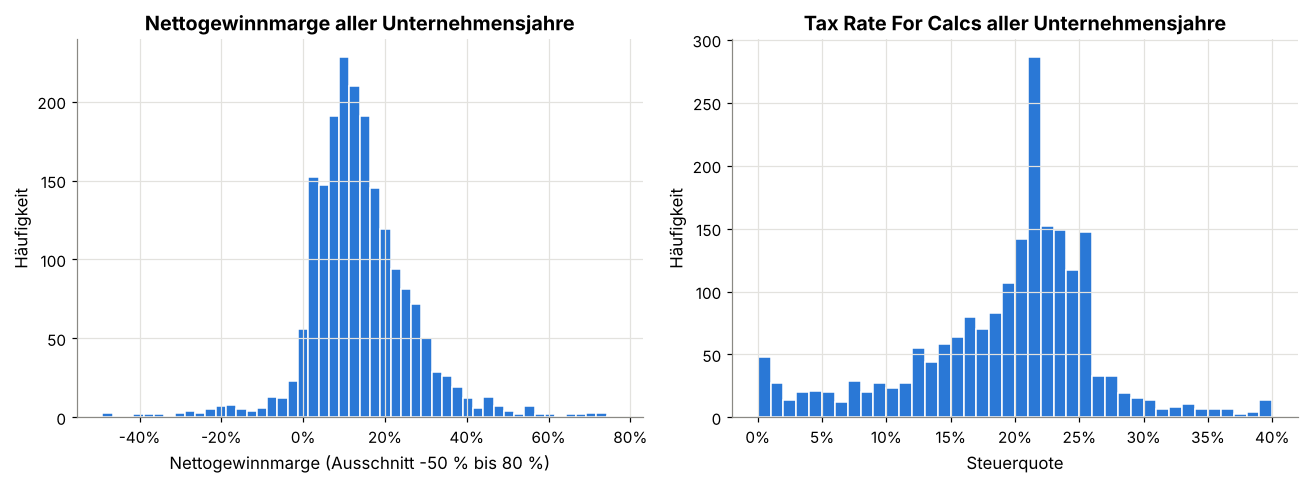

In [10]:
daten_sp["Nettomarge"] = daten_sp["Net Income"] / daten_sp["Total Revenue"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
marge = daten_sp["Nettomarge"].dropna()
ausserhalb = ((marge < -0.5) | (marge > 0.8)).sum()
axes[0].hist(marge[marge.between(-0.5, 0.8)], bins=50, color="#2a78d6", edgecolor="white")
axes[0].set_title("Nettogewinnmarge aller Unternehmensjahre")
axes[0].set_xlabel("Nettogewinnmarge (Ausschnitt -50 % bis 80 %)")
axes[0].set_ylabel("Häufigkeit")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))

axes[1].hist(daten_sp["Tax Rate For Calcs"], bins=40, color="#2a78d6", edgecolor="white")
axes[1].set_title("Tax Rate For Calcs aller Unternehmensjahre")
axes[1].set_xlabel("Steuerquote")
axes[1].set_ylabel("Häufigkeit")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
plt.show()

print(f"Nettomarge: n = {len(marge):,}, Median = {marge.median():.1%}, Minimum = {marge.min():.1%}, Maximum = {marge.max():.1%}")
print(f"Werte außerhalb des dargestellten Ausschnitts: {ausserhalb}")
print(f"Steuerquote: Median = {daten_sp['Tax Rate For Calcs'].median():.1%}, Anteil exakt 0 %: {(daten_sp['Tax Rate For Calcs'] == 0).mean():.1%}")

**Beobachtungen:**
- Die Nettogewinnmarge ist stark um den Median von 12,3 % konzentriert, hat aber **extreme Ausreißer** (Minimum −1.285,9 %, Maximum 204,4 %). 36 Werte liegen außerhalb des dargestellten Ausschnitts.
- Die Steuerquote hat ihren Median bei 21,0 % und eine deutliche Häufung genau bei diesem Wert (siehe 3.6).

**Folgerung für die Analyse:** Die Pearson-Korrelation reagiert empfindlich auf Ausreißer. In FF3 wird deshalb zusätzlich die robuste Spearman-Rangkorrelation berechnet.

---
## Phase 4: Datenauswertung und -analyse

### Forschungsfrage 1: Entwicklung des durchschnittlichen Total Revenue
**Vorgehen:** Umsatz je Unternehmen und Geschäftsjahr, anschließend Mittelwert und Median je Geschäftsjahr. Da nicht in jedem Geschäftsjahr alle fünf Unternehmen enthalten sind, wird die Anzahl `n` mit ausgewiesen. Ein fairer Vergleich ist nur in Jahren mit allen fünf Unternehmen möglich (**balanciertes Panel**), sonst würde allein das Fehlen eines Unternehmens den Durchschnitt verschieben.

In [11]:
umsatz = big5.pivot_table(index="GJ", columns="Symbol", values="Total Revenue")[UNTERNEHMEN] / MRD

ff1 = pd.DataFrame({
    "Mittelwert (Mrd. USD)": umsatz.mean(axis=1),
    "Median (Mrd. USD)": umsatz.median(axis=1),
    "n Unternehmen": umsatz.count(axis=1),
})
ff1["alle 5 enthalten"] = ff1["n Unternehmen"] == 5
mittel_bal = ff1["Mittelwert (Mrd. USD)"].where(ff1["alle 5 enthalten"])
ff1["Veränderung ggü. Vorjahr"] = (mittel_bal / mittel_bal.shift(1) - 1).map(lambda v: f"{v:+.1%}" if pd.notna(v) else "–")
display(ff1.round(1))

print("Umsatz je Unternehmen (Mrd. USD):")
display(umsatz.round(1))

,Mittelwert (Mrd. USD),Median (Mrd. USD),n Unternehmen,alle 5 enthalten,Veränderung ggü. Vorjahr
GJ,,,,,
2022,318.2,338.6,4,False,–
2023,314.8,307.4,5,True,–
2024,344.4,350.0,5,True,+9.4%
2025,382.5,402.8,5,True,+11.1%
2026,331.8,331.8,1,False,–


Umsatz je Unternehmen (Mrd. USD):


Symbol,AAPL,MSFT,AMZN,TSLA,GOOGL
GJ,,,,,
2022,394.3,NaN,514.0,81.5,282.8
2023,383.3,211.9,574.8,96.8,307.4
2024,391.0,245.1,638.0,97.7,350.0
2025,416.2,281.7,716.9,94.8,402.8
2026,NaN,331.8,NaN,NaN,NaN


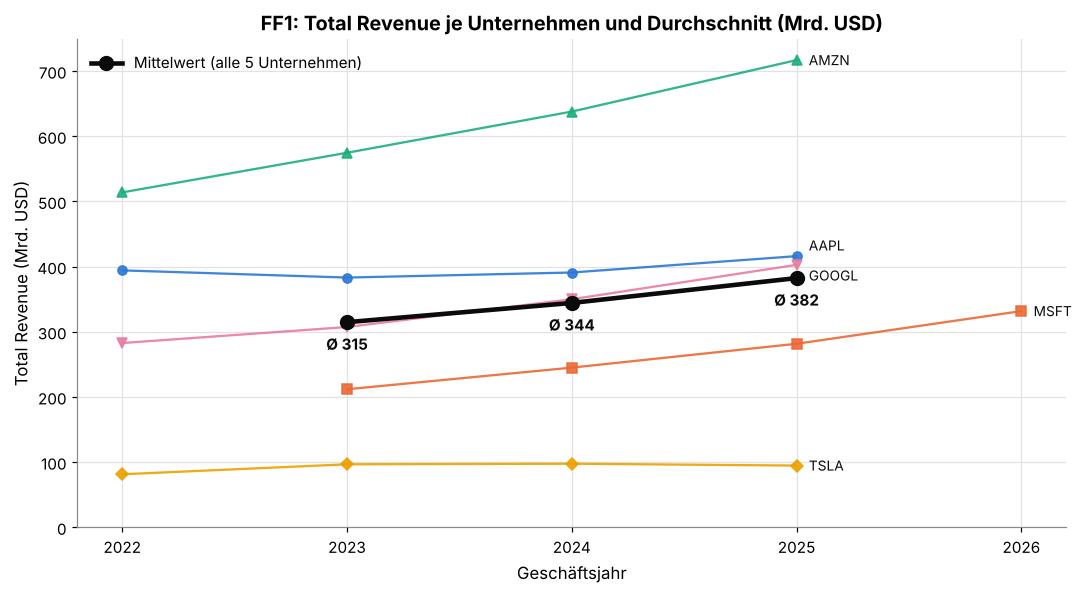

In [12]:
fig, ax = plt.subplots(figsize=(10, 5.5))
versatz = {"AAPL": 7, "GOOGL": -7}  # vertikaler Versatz, damit sich die Beschriftungen nicht überlappen
for sym in UNTERNEHMEN:
    s = umsatz[sym].dropna()
    ax.plot(s.index, s.values, color=FARBEN[sym], marker=MARKER[sym], markersize=6, linewidth=1.5, alpha=0.9)
    ax.annotate(sym, (s.index[-1], s.values[-1]), xytext=(8, versatz.get(sym, 0)), textcoords="offset points",
                va="center", fontsize=9, color=DUNKEL)

bal = mittel_bal.dropna()
ax.plot(bal.index, bal.values, color=DUNKEL, linewidth=3, marker="o", markersize=9, label="Mittelwert (alle 5 Unternehmen)")
for gj, wert in bal.items():
    ax.annotate(f"Ø {wert:.0f}", (gj, wert), xytext=(0, -18), textcoords="offset points", ha="center",
                fontsize=10, fontweight="bold", color=DUNKEL)

ax.set_title("FF1: Total Revenue je Unternehmen und Durchschnitt (Mrd. USD)")
ax.set_xlabel("Geschäftsjahr")
ax.set_ylabel("Total Revenue (Mrd. USD)")
ax.set_xticks(umsatz.index)
ax.set_ylim(0, None)
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

**Ergebnis FF1:**
- Im **balancierten Zeitraum 2023–2025** (alle fünf Unternehmen enthalten) steigt der durchschnittliche Total Revenue von **314,8 Mrd. USD** (2023) auf **344,4 Mrd. USD** (2024, +9,4 %) und **382,5 Mrd. USD** (2025, +11,1 %). Das Wachstum hat sich also beschleunigt.
- Auch der Median steigt (307,4 → 350,0 → 402,8 Mrd. USD). Der Anstieg wird also nicht nur von einem einzelnen Unternehmen getragen.
- Die Werte für 2022 (318,2 Mrd. USD) und 2026 (331,8 Mrd. USD) sind **nicht vergleichbar**: 2022 fehlt Microsoft, 2026 ist nur Microsoft enthalten. Ein naiver Vergleich über alle Jahre würde Rückgänge (2022→2023 und 2025→2026) zeigen, die nur durch die wechselnde Zusammensetzung entstehen.
- Auf Unternehmensebene ist Amazon in allen Jahren 2022–2025 das umsatzstärkste Unternehmen (2025: 716,9 Mrd. USD). Amazon, Alphabet und Microsoft steigern ihren Umsatz in jedem Jahr. Rückgänge gibt es nur bei Apple 2023 (394,3 → 383,3 Mrd. USD) und Tesla 2025 (97,7 → 94,8 Mrd. USD).

**H1 wird für den vergleichbaren Zeitraum 2023–2025 bestätigt.**

### Forschungsfrage 2: Höchster Net Income in der aktuellsten Periode
**Vorgehen:** „Aktuellste Periode“ ist wegen der unterschiedlichen Geschäftsjahre nicht eindeutig. Das neueste Datum im Datensatz (30.06.2026) betrifft nur Microsoft. Deshalb werden zwei Sichtweisen verglichen:
1. **jeweils letzter verfügbarer Jahresabschluss** je Unternehmen,
2. **gemeinsames Geschäftsjahr 2025**, in dem alle fünf Unternehmen enthalten sind.

In [13]:
letzte = (big5.sort_values("Period").groupby("Symbol").tail(1)
              [["Symbol", "Period", "Net Income"]].sort_values("Net Income", ascending=False))
letzte["Net Income (Mrd. USD)"] = (letzte["Net Income"] / MRD).round(2)
letzte["Period"] = letzte["Period"].dt.date
print("Sicht 1 – letzter verfügbarer Jahresabschluss:")
display(letzte[["Symbol", "Period", "Net Income (Mrd. USD)"]].reset_index(drop=True))

gj2025 = big5[big5["GJ"] == 2025][["Symbol", "Period", "Net Income"]].sort_values("Net Income", ascending=False)
gj2025["Net Income (Mrd. USD)"] = (gj2025["Net Income"] / MRD).round(2)
gj2025["Period"] = gj2025["Period"].dt.date
print("Sicht 2 – gemeinsames Geschäftsjahr 2025:")
display(gj2025[["Symbol", "Period", "Net Income (Mrd. USD)"]].reset_index(drop=True))

Sicht 1 – letzter verfügbarer Jahresabschluss:


,Symbol,Period,Net Income (Mrd. USD)
0,MSFT,2026-06-30,133.75
1,GOOGL,2025-12-31,132.17
2,AAPL,2025-09-30,112.01
3,AMZN,2025-12-31,77.67
4,TSLA,2025-12-31,3.79


Sicht 2 – gemeinsames Geschäftsjahr 2025:


,Symbol,Period,Net Income (Mrd. USD)
0,GOOGL,2025-12-31,132.17
1,AAPL,2025-09-30,112.01
2,MSFT,2025-06-30,101.83
3,AMZN,2025-12-31,77.67
4,TSLA,2025-12-31,3.79


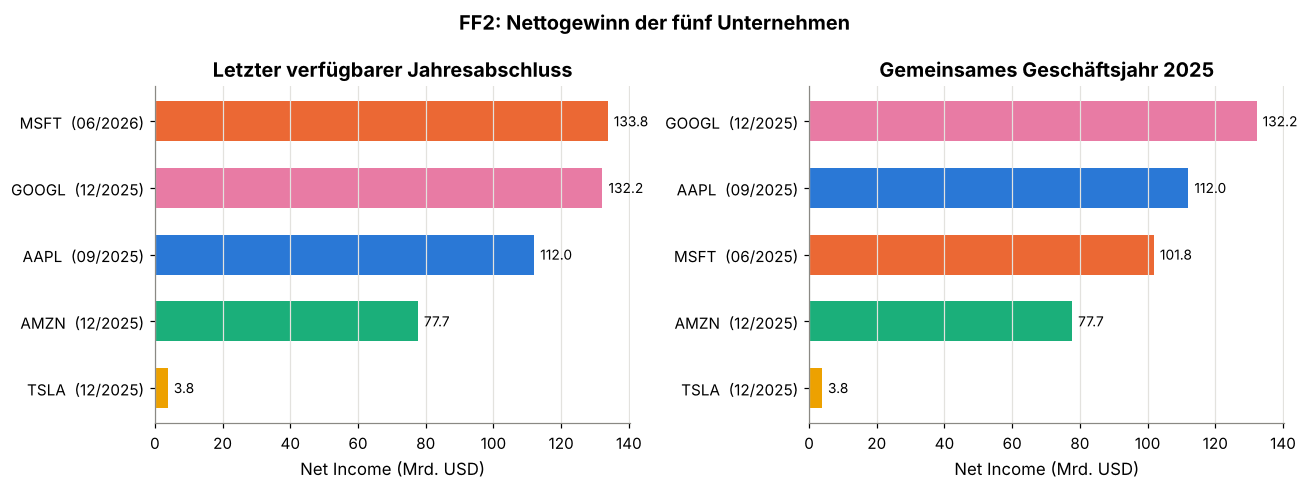

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, tab, titel in [(axes[0], letzte, "Letzter verfügbarer Jahresabschluss"),
                       (axes[1], gj2025, "Gemeinsames Geschäftsjahr 2025")]:
    t = tab.iloc[::-1]  # größter Wert oben
    beschr = [f"{s}  ({p:%m/%Y})" for s, p in zip(t["Symbol"], pd.to_datetime(t["Period"]))]
    ax.barh(beschr, t["Net Income (Mrd. USD)"], color=[FARBEN[s] for s in t["Symbol"]], height=0.6)
    for y, v in enumerate(t["Net Income (Mrd. USD)"]):
        ax.annotate(f"{v:.1f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_title(titel)
    ax.set_xlabel("Net Income (Mrd. USD)")
    ax.grid(axis="y", visible=False)
fig.suptitle("FF2: Nettogewinn der fünf Unternehmen", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

**Ergänzung (ursprüngliche Fragestellung): Top 10 im gesamten Datensatz.** Je Unternehmen wird der letzte verfügbare Jahresabschluss verwendet, Doppellistungen sind bereits entfernt (siehe 3.3).

,Symbol,Period,Net Income (Mrd. USD)
0,MSFT,2026-06-30,133.75
1,GOOGL,2025-12-31,132.17
2,NVDA,2026-01-31,120.07
3,AAPL,2025-09-30,112.01
4,AMZN,2025-12-31,77.67
5,META,2025-12-31,60.46
6,JPM,2025-12-31,57.05
7,BAC,2025-12-31,30.51
8,XOM,2025-12-31,28.84
9,JNJ,2025-12-31,26.80


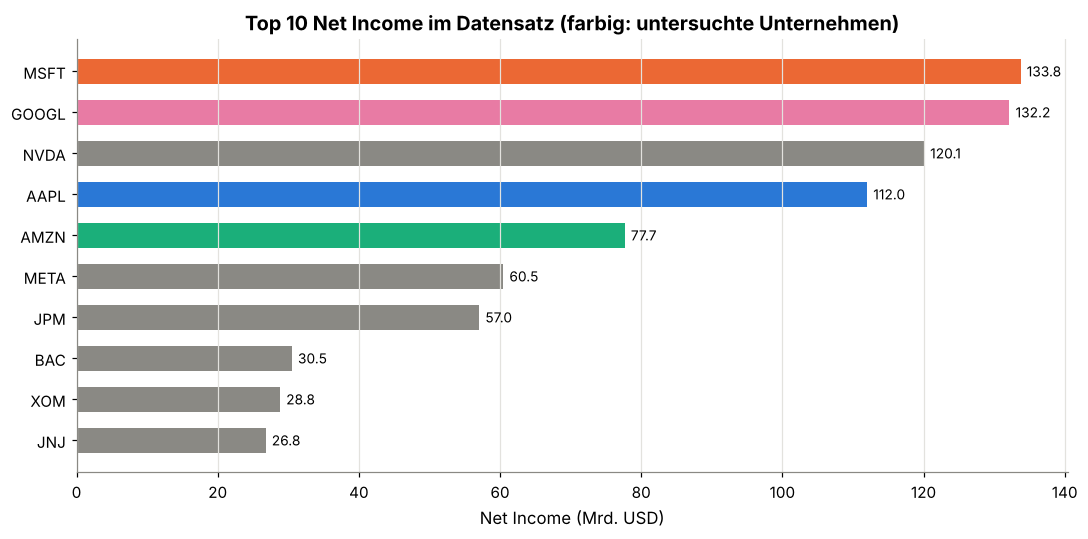

In [15]:
top10 = (daten_sp.sort_values("Period").groupby("Symbol").tail(1)
                 .nlargest(10, "Net Income")[["Symbol", "Period", "Net Income"]])
top10["Net Income (Mrd. USD)"] = (top10["Net Income"] / MRD).round(2)
top10["Period"] = top10["Period"].dt.date
display(top10[["Symbol", "Period", "Net Income (Mrd. USD)"]].reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 5))
t = top10.iloc[::-1]
ax.barh(t["Symbol"], t["Net Income (Mrd. USD)"],
        color=[FARBEN.get(s, GRAU) for s in t["Symbol"]], height=0.6)
for y, v in enumerate(t["Net Income (Mrd. USD)"]):
    ax.annotate(f"{v:.1f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_title("Top 10 Net Income im Datensatz (farbig: untersuchte Unternehmen)")
ax.set_xlabel("Net Income (Mrd. USD)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Ergebnis FF2:** Die Antwort hängt von der Definition der „aktuellsten Periode“ ab.
- **Letzter verfügbarer Jahresabschluss:** Microsoft liegt mit 133,75 Mrd. USD (Geschäftsjahr bis 30.06.2026) knapp vor Alphabet mit 132,17 Mrd. USD (bis 31.12.2025). Der Abstand beträgt nur 1,58 Mrd. USD (rund 1,2 %).
- **Gemeinsames Geschäftsjahr 2025:** Alphabet liegt vorn (132,17 Mrd. USD), vor Apple (112,01) und Microsoft (101,83).

In Sicht 2 enden alle Abschlüsse im selben Kalenderjahr, deshalb ist sie der fairere Vergleich: **Alphabet hatte im Geschäftsjahr 2025 den höchsten Nettogewinn.** Amazon ist zwar das umsatzstärkste Unternehmen (FF1), liegt beim Nettogewinn aber nur auf Platz 4. Tesla hat mit 3,79 Mrd. USD den mit Abstand niedrigsten Nettogewinn. **H2 wird damit nicht bestätigt.**

**Top 10 im Gesamtdatensatz:** Vier der fünf untersuchten Unternehmen (MSFT, GOOGL, AAPL, AMZN) gehören zu den zehn gewinnstärksten Unternehmen des Datensatzes. Dazu kommen NVDA (Platz 3), META, JPM, BAC, XOM und JNJ. Tesla gehört nicht zu den Top 10.

### Forschungsfrage 3: Steuerquote und Nettogewinnmarge
**Vorgehen:** Neues Feature **Nettogewinnmarge = Net Income / Total Revenue**. Zusammenhang mit `Tax Rate For Calcs` über
- **Pearson-Korrelation** (linearer Zusammenhang, empfindlich gegenüber Ausreißern) und
- **Spearman-Rangkorrelation** (monotoner Zusammenhang, robust gegenüber Ausreißern).

Signifikanzniveau: α = 0,05. Nullhypothese: Es besteht kein Zusammenhang (ρ = 0).

In [16]:
big5["Nettomarge"] = big5["Net Income"] / big5["Total Revenue"]
x, y = big5["Tax Rate For Calcs"], big5["Nettomarge"]

r_p, p_p = stats.pearsonr(x, y)
r_s, p_s = stats.spearmanr(x, y)
print(f"Fünf Unternehmen, n = {len(big5)} Unternehmensjahre")
print(f"Pearson  r   = {r_p:+.3f}   p = {p_p:.3f}   Bestimmtheitsmaß r² = {r_p**2:.3f}")
print(f"Spearman rho = {r_s:+.3f}   p = {p_s:.3f}")

display(big5[["Symbol", "GJ", "Tax Rate For Calcs", "Nettomarge"]]
        .assign(**{"Tax Rate For Calcs": lambda d: (d["Tax Rate For Calcs"] * 100).round(1),
                   "Nettomarge": lambda d: (d["Nettomarge"] * 100).round(1)})
        .rename(columns={"Tax Rate For Calcs": "Steuerquote (%)", "Nettomarge": "Nettomarge (%)"})
        .set_index(["Symbol", "GJ"]))

Fünf Unternehmen, n = 20 Unternehmensjahre
Pearson  r   = -0.219   p = 0.354   Bestimmtheitsmaß r² = 0.048
Spearman rho = -0.243   p = 0.302


Steuerquote (%)  Nettomarge (%)
Symbol GJ                                   
AAPL   2022             16.2            25.3
       2023             14.7            25.3
       2024             24.1            24.0
       2025             15.6            26.9
AMZN   2022             21.0            -0.5
       2023             19.0             5.3
       2024             13.5             9.3
       2025             19.6            10.8
GOOGL  2022             15.9            21.2
       2023             13.9            24.0
       2024             16.4            28.6
       2025             16.8            32.8
MSFT   2023             19.0            34.1
       2024             18.2            36.0
       2025             17.6            36.1
       2026             19.4            40.3
TSLA   2022              8.0            15.4
       2023             21.0            15.5
       2024             20.0             7.3
       2025             27.0             4.0

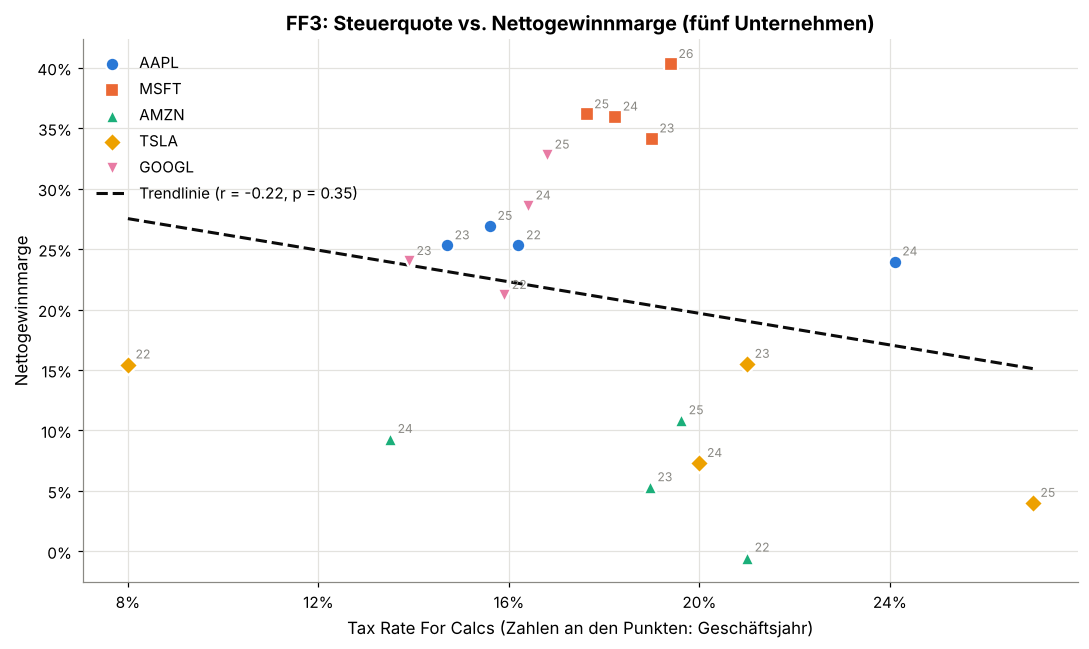

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
for sym in UNTERNEHMEN:
    d = big5[big5["Symbol"] == sym]
    ax.scatter(d["Tax Rate For Calcs"], d["Nettomarge"], s=80, color=FARBEN[sym], marker=MARKER[sym],
               edgecolor="white", linewidth=1.5, label=sym, zorder=3)
    for _, z in d.iterrows():
        ax.annotate(str(z["GJ"])[2:], (z["Tax Rate For Calcs"], z["Nettomarge"]), xytext=(5, 4),
                    textcoords="offset points", fontsize=8, color=GRAU)

steigung, achse = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, achse + steigung * xs, color=DUNKEL, linewidth=2, linestyle="--",
        label=f"Trendlinie (r = {r_p:+.2f}, p = {p_p:.2f})")
ax.set_title("FF3: Steuerquote vs. Nettogewinnmarge (fünf Unternehmen)")
ax.set_xlabel("Tax Rate For Calcs (Zahlen an den Punkten: Geschäftsjahr)")
ax.set_ylabel("Nettogewinnmarge")
ax.xaxis.set_major_locator(plt.MultipleLocator(0.04))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Erweiterung über alle Unternehmen des Datensatzes:** Bei nur 20 Beobachtungen ist die Aussagekraft begrenzt. Deshalb wird dieselbe Analyse auf den bereinigten Gesamtdatensatz angewendet. Wegen der extremen Ausreißer (siehe Häufigkeitsverteilung 3.7) wird zusätzlich eine Pearson-Korrelation ohne das oberste und unterste Prozent der Margen berechnet.

In [18]:
alle = daten_sp.dropna(subset=["Nettomarge", "Tax Rate For Calcs"])
untere, obere = alle["Nettomarge"].quantile([0.01, 0.99])
getrimmt = alle[alle["Nettomarge"].between(untere, obere)]

ergebnisse = []
for name, d, methode in [("Pearson, alle Werte", alle, stats.pearsonr),
                         ("Spearman, alle Werte", alle, stats.spearmanr),
                         ("Pearson, ohne 1 %-Ränder", getrimmt, stats.pearsonr)]:
    r, p = methode(d["Tax Rate For Calcs"], d["Nettomarge"])
    ergebnisse.append({"Verfahren": name, "n": len(d), "Koeffizient": round(r, 3), "p-Wert": f"{p:.2g}",
                       "signifikant (α = 0,05)": p < 0.05})
display(pd.DataFrame(ergebnisse))
print(f"Getrimmter Bereich der Nettomarge: {untere:.1%} bis {obere:.1%}")

,Verfahren,n,Koeffizient,p-Wert,"signifikant (α = 0,05)"
0,"Pearson, alle Werte",2016,0.042,0.059,False
1,"Spearman, alle Werte",2016,-0.215,1.9e-22,True
2,"Pearson, ohne 1 %-Ränder",1974,-0.142,2.1e-10,True


Getrimmter Bereich der Nettomarge: -86.7% bis 57.4%


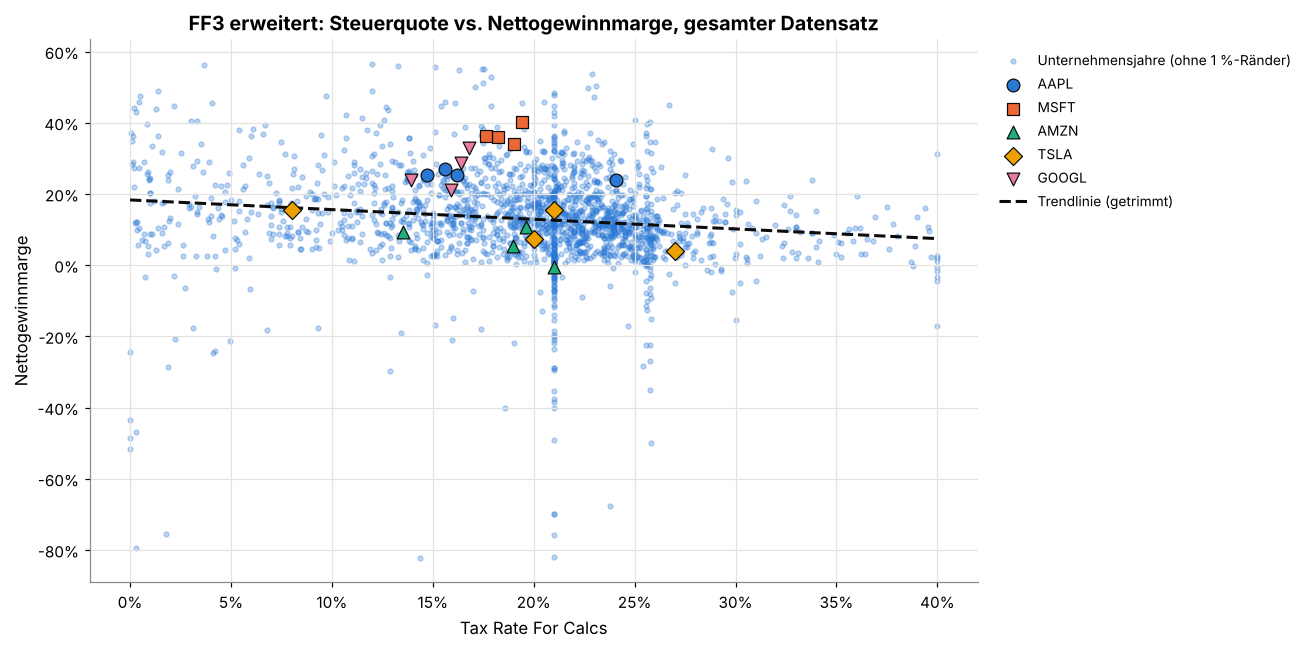

In [19]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(getrimmt["Tax Rate For Calcs"], getrimmt["Nettomarge"], s=10, color="#2a78d6", alpha=0.3,
           label="Unternehmensjahre (ohne 1 %-Ränder)")
for sym in UNTERNEHMEN:
    d = big5[big5["Symbol"] == sym]
    ax.scatter(d["Tax Rate For Calcs"], d["Nettomarge"], s=70, color=FARBEN[sym], marker=MARKER[sym],
               edgecolor=DUNKEL, linewidth=0.8, label=sym, zorder=3)
m, b = np.polyfit(getrimmt["Tax Rate For Calcs"], getrimmt["Nettomarge"], 1)
xs = np.linspace(0, getrimmt["Tax Rate For Calcs"].max(), 50)
ax.plot(xs, b + m * xs, color=DUNKEL, linestyle="--", linewidth=2, label="Trendlinie (getrimmt)")
ax.set_title("FF3 erweitert: Steuerquote vs. Nettogewinnmarge, gesamter Datensatz")
ax.set_xlabel("Tax Rate For Calcs")
ax.set_ylabel("Nettogewinnmarge")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Ergebnis FF3:**
- **Fünf Unternehmen (n = 20):** Pearson r = −0,22 (p = 0,35), Spearman ρ = −0,24 (p = 0,30). Die Richtung ist leicht negativ, der Zusammenhang aber **nicht signifikant**. Die Steuerquote erklärt nur rund 5 % der Streuung der Marge (r² = 0,048).
- Die Unterschiede in der Marge entstehen vor allem **zwischen den Unternehmen**: Microsoft erreicht 34,1–40,3 %, Amazon −0,5 bis 10,8 %, bei vergleichbaren Steuerquoten. Bei Tesla steigt die Steuerquote von 8,0 % (2022) auf 27,0 % (2025), während die Marge von 15,4 % auf 4,0 % sinkt (der Wert 2023 ist allerdings ein ersetzter Wert, siehe 3.6).
- **Gesamtdatensatz (n = 2.016):** Pearson über alle Werte ergibt r = +0,04 (p = 0,059, nicht signifikant), wird aber durch die extremen Ausreißer verzerrt. Die robuste Spearman-Korrelation (ρ = −0,215) und Pearson ohne die 1-%-Ränder (r = −0,142) sind beide **signifikant negativ** (p < 0,001).

**Interpretation:** Es gibt einen **schwachen negativen Zusammenhang**: Unternehmensjahre mit höherer Steuerquote haben tendenziell eine etwas niedrigere Nettomarge. Signifikant wird er nur durch die große Stichprobe, der Effekt ist klein (r² ≈ 2–5 %). Bei den fünf Big-Tech-Unternehmen lässt er sich nicht nachweisen. **H3 wird für den Gesamtdatensatz schwach bestätigt, für die fünf Unternehmen nicht.** Eine Korrelation belegt außerdem keine Ursache-Wirkungs-Beziehung.

### Forschungsfrage 4: Volatilität des Diluted EPS und Sondereffekte
**Vorgehen:**
1. **Standardabweichung** des Diluted EPS je Unternehmen (absolute Schwankung in USD).
2. **Variationskoeffizient** VK = Standardabweichung / |Mittelwert|. Die EPS-Niveaus sind sehr unterschiedlich (Microsoft um 13 USD, Tesla um 3 USD), deshalb wird die Schwankung zusätzlich relativ gemessen.
3. **Sondereffekte:** Anteil des Steuereffekts der Sondereffekte (Tax Effect Of Unusual Items) und der Sondereffekte vor Steuern (Total Unusual Items) am Nettogewinn.
4. **Bereinigtes EPS** = Normalized Income / Diluted Average Shares. Wenn die Schwankung des bereinigten EPS deutlich kleiner ist, erklären Sondereffekte einen Teil der Volatilität.

Zunächst wird geprüft, wie Normalized Income im Datensatz mit den Sondereffekten zusammenhängt:

In [20]:
rekonstruiert = big5["Net Income"] - big5["Total Unusual Items"].fillna(0) + big5["Tax Effect Of Unusual Items"]
abweichung = (rekonstruiert - big5["Normalized Income"]).abs().max()
print("Prüfung: Normalized Income = Net Income − Total Unusual Items + Tax Effect Of Unusual Items")
print(f"Größte Abweichung über alle 20 Unternehmensjahre: {abweichung:,.0f} USD")
print("Hinweis: Für AAPL ist Total Unusual Items nicht befüllt (NaN), der Steuereffekt ist in allen Jahren 0.")

Prüfung: Normalized Income = Net Income − Total Unusual Items + Tax Effect Of Unusual Items
Größte Abweichung über alle 20 Unternehmensjahre: 0 USD
Hinweis: Für AAPL ist Total Unusual Items nicht befüllt (NaN), der Steuereffekt ist in allen Jahren 0.


In [21]:
big5["EPS bereinigt"] = big5["Normalized Income"] / big5["Diluted Average Shares"]

def betrag_mittel(s):
    return s.abs().mean()

ff4 = big5.groupby("Symbol").agg(
    eps_mittel=("Diluted EPS", "mean"),
    eps_std=("Diluted EPS", "std"),
    eps_bereinigt_std=("EPS bereinigt", "std"),
    steuereffekt=("Tax Effect Of Unusual Items", betrag_mittel),
    sondereffekte=("Total Unusual Items", betrag_mittel),
    nettogewinn=("Net Income", betrag_mittel),
).reindex(UNTERNEHMEN)

ff4["VK"] = ff4["eps_std"] / ff4["eps_mittel"].abs()
ff4["Rückgang Std. durch Bereinigung"] = 1 - ff4["eps_bereinigt_std"] / ff4["eps_std"]
ff4["Steuereffekt / Nettogewinn"] = ff4["steuereffekt"] / ff4["nettogewinn"]
ff4["Sondereffekte / Nettogewinn"] = ff4["sondereffekte"] / ff4["nettogewinn"]

tabelle4 = pd.DataFrame({
    "Ø EPS (USD)": ff4["eps_mittel"].round(2),
    "Std. EPS (USD)": ff4["eps_std"].round(2),
    "VK": ff4["VK"].round(2),
    "Std. EPS bereinigt (USD)": ff4["eps_bereinigt_std"].round(2),
    "Rückgang Std.": ff4["Rückgang Std. durch Bereinigung"].map(lambda v: f"{abs(v):.0%}" if abs(v) < 0.005 else f"{v:.0%}"),
    "Ø |Steuereffekt| / Ø |Nettogewinn|": ff4["Steuereffekt / Nettogewinn"].map("{:.1%}".format),
    "Ø |Sondereffekte| / Ø |Nettogewinn|": ff4["Sondereffekte / Nettogewinn"].map(lambda v: f"{v:.1%}" if pd.notna(v) else "nicht befüllt"),
}).sort_values("Std. EPS (USD)", ascending=False)
display(tabelle4)

print("Ranking absolute Volatilität (Std.):", " > ".join(ff4["eps_std"].sort_values(ascending=False).index))
print("Ranking relative Volatilität (VK):   ", " > ".join(ff4["VK"].sort_values(ascending=False).index))
print("Ranking Steuereffekt-Anteil:         ", " > ".join(ff4["Steuereffekt / Nettogewinn"].sort_values(ascending=False).index))

print("\nEPS je Geschäftsjahr (berichtet vs. bereinigt):")
display(big5.pivot_table(index="GJ", columns="Symbol", values=["Diluted EPS", "EPS bereinigt"])
            .round(2).reindex(columns=UNTERNEHMEN, level=1))

print("\nSondereffekte vor Steuern (Total Unusual Items, Mrd. USD; AAPL nicht befüllt):")
display((big5.pivot_table(index="GJ", columns="Symbol", values="Total Unusual Items") / MRD)
            .reindex(columns=UNTERNEHMEN).round(2))

,Ø EPS (USD),Std. EPS (USD),VK,Std. EPS bereinigt (USD),Rückgang Std.,Ø |Steuereffekt| / Ø |Nettogewinn|,Ø |Sondereffekte| / Ø |Nettogewinn|
Symbol,,,,,,,
MSFT,13.27,3.52,0.27,3.24,8%,0.3%,1.7%
AMZN,3.83,3.25,0.85,2.40,26%,4.0%,20.3%
GOOGL,7.30,2.75,0.38,1.89,31%,1.6%,9.5%
TSLA,2.76,1.47,0.53,1.39,5%,0.7%,3.5%
AAPL,6.44,0.68,0.11,0.68,0%,0.0%,nicht befüllt


Ranking absolute Volatilität (Std.): MSFT > AMZN > GOOGL > TSLA > AAPL
Ranking relative Volatilität (VK):    AMZN > TSLA > GOOGL > MSFT > AAPL
Ranking Steuereffekt-Anteil:          AMZN > GOOGL > TSLA > MSFT > AAPL

EPS je Geschäftsjahr (berichtet vs. bereinigt):


Diluted EPS                           EPS bereinigt                         
Symbol        AAPL   MSFT  AMZN  TSLA  GOOGL          AAPL   MSFT  AMZN  TSLA GOOGL
GJ                                                                                 
2022          6.11    NaN -0.27  3.62   4.56          6.11    NaN  0.99  3.67  4.95
2023          6.13   9.68  2.90  4.31   5.80          6.13   9.69  2.82  4.31  5.94
2024          6.08  11.80  5.53  2.04   8.04          6.08  11.86  5.67  2.39  7.89
2025          7.46  13.64  7.17  1.08  10.81          7.46  13.69  6.04  1.18  9.16
2026           NaN  17.95   NaN   NaN    NaN           NaN  17.33   NaN   NaN   NaN


Sondereffekte vor Steuern (Total Unusual Items, Mrd. USD; AAPL nicht befüllt):


Symbol,AAPL,MSFT,AMZN,TSLA,GOOGL
GJ,,,,,
2022,NaN,NaN,-16.27,-0.18,-6.17
2023,NaN,-0.02,1.05,0.00,-2.06
2024,NaN,-0.55,-1.84,-0.68,2.26
2025,NaN,-0.44,15.32,-0.49,24.24
2026,NaN,5.72,NaN,NaN,NaN


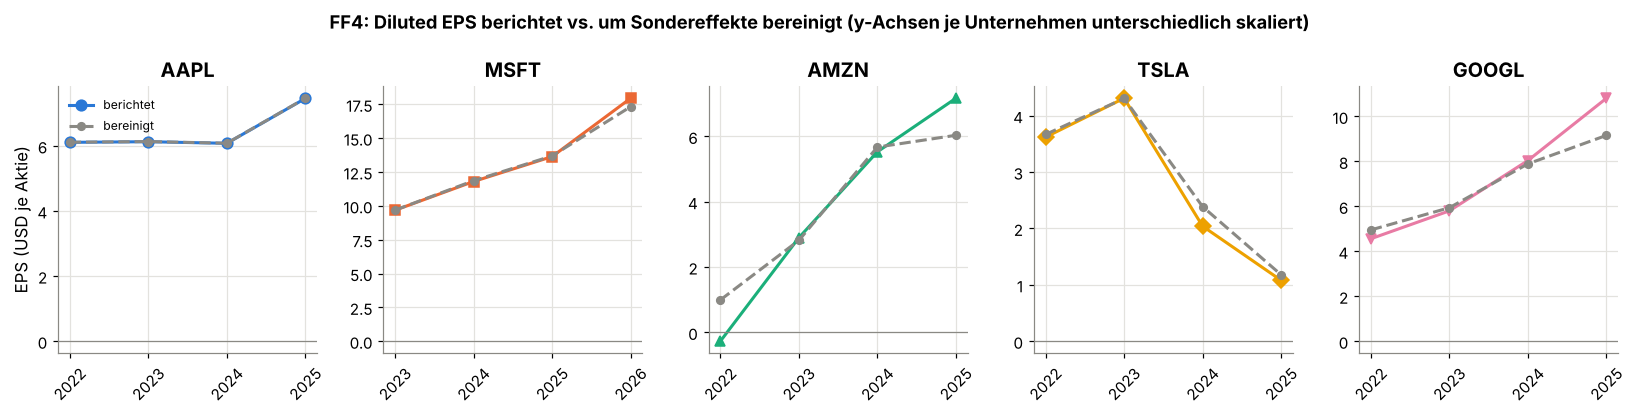

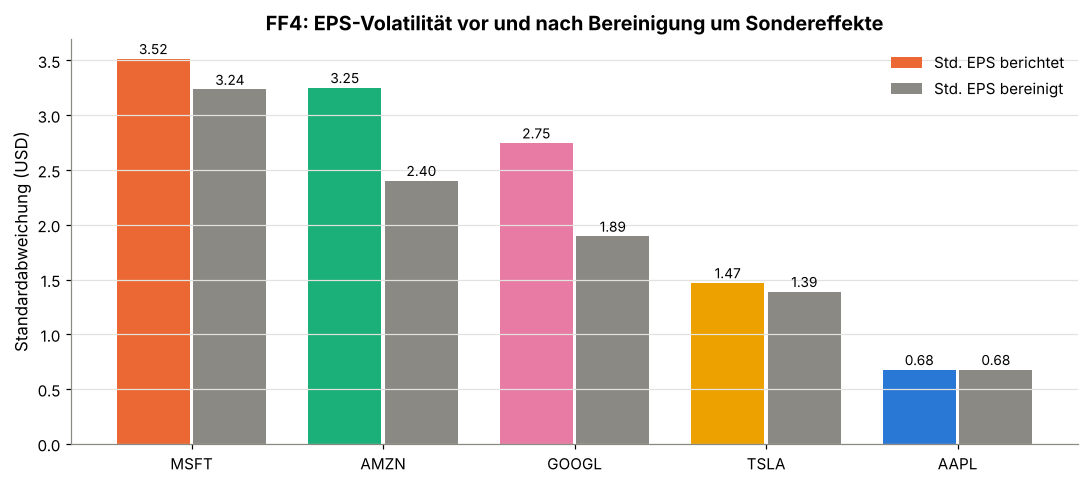

In [22]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.8), sharey=False)
for ax, sym in zip(axes, UNTERNEHMEN):
    d = big5[big5["Symbol"] == sym].sort_values("GJ")
    ax.plot(d["GJ"], d["Diluted EPS"], color=FARBEN[sym], marker=MARKER[sym], markersize=7, label="berichtet")
    ax.plot(d["GJ"], d["EPS bereinigt"], color=GRAU, linestyle="--", marker="o", markersize=5, label="bereinigt")
    ax.axhline(0, color=GRAU, linewidth=0.8)
    ax.set_title(sym)
    ax.set_xticks(d["GJ"])
    ax.tick_params(axis="x", labelrotation=45)
axes[0].set_ylabel("EPS (USD je Aktie)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("FF4: Diluted EPS berichtet vs. um Sondereffekte bereinigt (y-Achsen je Unternehmen unterschiedlich skaliert)",
             fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
reihen = ff4.sort_values("eps_std", ascending=False)
pos = np.arange(len(reihen))
ax.bar(pos - 0.2, reihen["eps_std"], width=0.38, color=[FARBEN[s] for s in reihen.index], label="Std. EPS berichtet")
ax.bar(pos + 0.2, reihen["eps_bereinigt_std"], width=0.38, color=GRAU, label="Std. EPS bereinigt")
for i, (a, b) in enumerate(zip(reihen["eps_std"], reihen["eps_bereinigt_std"])):
    ax.annotate(f"{a:.2f}", (i - 0.2, a), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
    ax.annotate(f"{b:.2f}", (i + 0.2, b), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(pos)
ax.set_xticklabels(reihen.index)
ax.set_ylabel("Standardabweichung (USD)")
ax.set_title("FF4: EPS-Volatilität vor und nach Bereinigung um Sondereffekte")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Ergebnis FF4 – Volatilität:**
- **Absolut:** Microsoft hat die höchste Standardabweichung (3,52 USD), vor Amazon (3,25) und Alphabet (2,75). Bei Microsoft ist das aber vor allem **stetiges Wachstum** (EPS 9,68 → 17,95 USD) und kein Auf und Ab: Bei einer steigenden Zeitreihe misst die Standardabweichung auch den Trend.
- **Relativ (VK):** Amazon ist mit VK = 0,85 klar am volatilsten, vor Tesla (0,53). Apple ist mit beiden Maßen am stabilsten (Std. 0,68 USD, VK 0,11).

**Erklärung durch Sondereffekte:**
- Der Steuereffekt der Sondereffekte ist im Verhältnis zum Nettogewinn bei Amazon am größten (4,0 %), gefolgt von Alphabet (1,6 %). Das passt zu Amazon als relativ volatilstem Unternehmen. Tesla hat dagegen trotz kleiner Sondereffekte (0,7 %) die zweithöchste relative Volatilität.
- Der Steuereffekt selbst ist klein. Größer sind die **Sondereffekte vor Steuern** (Total Unusual Items), bei Amazon im Schnitt 20,3 % des Nettogewinns. Rechnet man sie heraus (bereinigtes EPS), sinkt die Standardabweichung bei Alphabet um 31 % und bei Amazon um 26 %, bei Microsoft nur um 8 % und bei Tesla um 5 %.
- Deutlichstes Beispiel ist **Amazon 2022**: berichtetes EPS −0,27 USD, bereinigt +0,99 USD. Der Verlust in diesem Jahr geht rechnerisch auf Sondereffekte von −16,27 Mrd. USD zurück.

**Fazit:** Sondereffekte erklären einen **Teil** der EPS-Volatilität bei Amazon und Alphabet, aber nicht den Großteil. Der größere Teil bleibt nach der Bereinigung bestehen und spiegelt die operative Entwicklung wider (Gewinnwachstum bei Microsoft, Alphabet und Amazon, Gewinnrückgang bei Tesla). **H4 wird teilweise bestätigt.**

### Forschungsfrage 5: Anomalien im Operating Revenue
**Vorgehen in drei Schritten:**
1. **Rollierender Durchschnitt** (Fenster = 2 Jahre) als geglättete Vergleichslinie zur Umsatzzeitreihe.
2. **Unternehmensinterner Z-Score** der jährlichen Wachstumsrate: z = (Wachstum − Mittelwert des Unternehmens) / Standardabweichung des Unternehmens. Bei 4 Umsatzjahren gibt es nur **3 Wachstumsraten** je Unternehmen. Mathematisch kann der Betrag des Z-Scores bei n Werten höchstens (n − 1) / √n erreichen, bei n = 3 also 1,155. Der übliche Schwellenwert |z| > 2 kann daher **nie** erreicht werden; verwendet wird |z| > 1.
3. **Robuster Z-Score im Marktvergleich**: Das Wachstum jedes Unternehmens wird mit dem Wachstum aller Unternehmen des Datensatzes im selben Geschäftsjahr verglichen. Statt Mittelwert und Standardabweichung werden **Median und MAD** (Median der absoluten Abweichungen) verwendet, weil einzelne extreme Wachstumsraten die Standardabweichung stark aufblähen. Schwellenwert: |z| > 2.

In [23]:
n = 3
print(f"Maximal möglicher |Z-Score| bei n = {n} Werten: {(n - 1) / np.sqrt(n):.3f}")

big5 = big5.sort_values(["Symbol", "Period"])
big5["Rollierender Ø (2 J.)"] = big5.groupby("Symbol")["Operating Revenue"].transform(lambda s: s.rolling(2).mean())
big5["Wachstum"] = big5["Operating Revenue"] / big5.groupby("Symbol")["Operating Revenue"].shift(1) - 1
big5["z intern"] = big5.groupby("Symbol")["Wachstum"].transform(lambda s: (s - s.mean()) / s.std())

# Marktvergleich: Wachstum aller Unternehmen je Geschäftsjahr
markt = daten_sp.sort_values(["Symbol", "Period"]).copy()
markt["Wachstum"] = markt["Operating Revenue"] / markt.groupby("Symbol")["Operating Revenue"].shift(1) - 1
markt = markt.dropna(subset=["Wachstum"])
kennwerte = markt.groupby("GJ")["Wachstum"].agg(
    n="count", Mittelwert="mean", Standardabw="std", Median="median",
    MAD=lambda s: (s - s.median()).abs().median())
print("\nWachstum aller Unternehmen je Geschäftsjahr (Vergleichsbasis):")
display(kennwerte.round(3))

big5 = big5.merge(kennwerte[["Median", "MAD"]], left_on="GJ", right_index=True, how="left")
big5["z robust Markt"] = (big5["Wachstum"] - big5["Median"]) / (1.4826 * big5["MAD"])

ff5 = big5.dropna(subset=["Wachstum"])[["Symbol", "GJ", "Operating Revenue", "Wachstum", "z intern", "Median", "z robust Markt"]].copy()
ff5["Operating Revenue"] = (ff5["Operating Revenue"] / MRD).round(1)
ff5["Auffällig intern (|z| > 1)"] = ff5["z intern"].abs() > 1
ff5["Auffällig Markt (|z| > 2)"] = ff5["z robust Markt"].abs() > 2
ff5["Umsatzrückgang"] = ff5["Wachstum"] < 0
display(ff5.assign(Wachstum=lambda d: (d["Wachstum"] * 100).round(1),
                   Median=lambda d: (d["Median"] * 100).round(1))
           .round({"z intern": 2, "z robust Markt": 2})
           .rename(columns={"Operating Revenue": "Umsatz (Mrd. USD)", "Wachstum": "Wachstum (%)",
                            "Median": "Markt-Median (%)"})
           .set_index(["Symbol", "GJ"]))

Maximal möglicher |Z-Score| bei n = 3 Werten: 1.155

Wachstum aller Unternehmen je Geschäftsjahr (Vergleichsbasis):


,n,Mittelwert,Standardabw,Median,MAD
GJ,,,,,
2022,1,0.055,NaN,0.055,0.000
2023,436,0.162,1.973,0.052,0.074
2024,505,0.075,0.188,0.048,0.052
2025,504,0.098,0.180,0.064,0.045
2026,69,0.160,0.260,0.092,0.055


Umsatz (Mrd. USD)  Wachstum (%)  z intern  Markt-Median (%)  z robust Markt  Auffällig intern (|z| > 1)  Auffällig Markt (|z| > 2)  Umsatzrückgang
Symbol GJ                                                                                                                                                      
AAPL   2023              383.3          -2.8     -1.01               5.2           -0.73                        True                      False            True
       2024              391.0           2.0      0.03               4.8           -0.36                       False                      False           False
       2025              416.2           6.4      0.98               6.4           -0.00                       False                      False           False
AMZN   2023              574.8          11.8      0.14               5.2            0.60                       False                      False           False
       2024              638.0          11.0     -1.06               4.8            0.81                        True                      False           False
       2025              716.9          12.4      0.92               6.4            0.89                       False                      False           False
GOOGL  2023              307.4           8.7     -1.14               5.2            0.32                        True                      False           False
       2024              350.0          13.9      0.39               4.8            1.19                       False                      False           False
       2025              402.8          15.1      0.75               6.4            1.30                       False                      False           False
MSFT   2024              245.1          15.7     -0.31               4.8            1.42                       False                      False           False
       2025              281.7          14.9     -0.81               6.4            1.28                       False                      False           False
       2026              331.8          17.8      1.12               9.2            1.07                        True                      False           False
TSLA   2023               96.8          18.8      1.14               5.2            1.24                        True                      False           False
       2024               97.7           0.9     -0.40               4.8           -0.50                       False                      False           False
       2025               94.8          -2.9     -0.74               6.4           -1.41                       False                      False            True

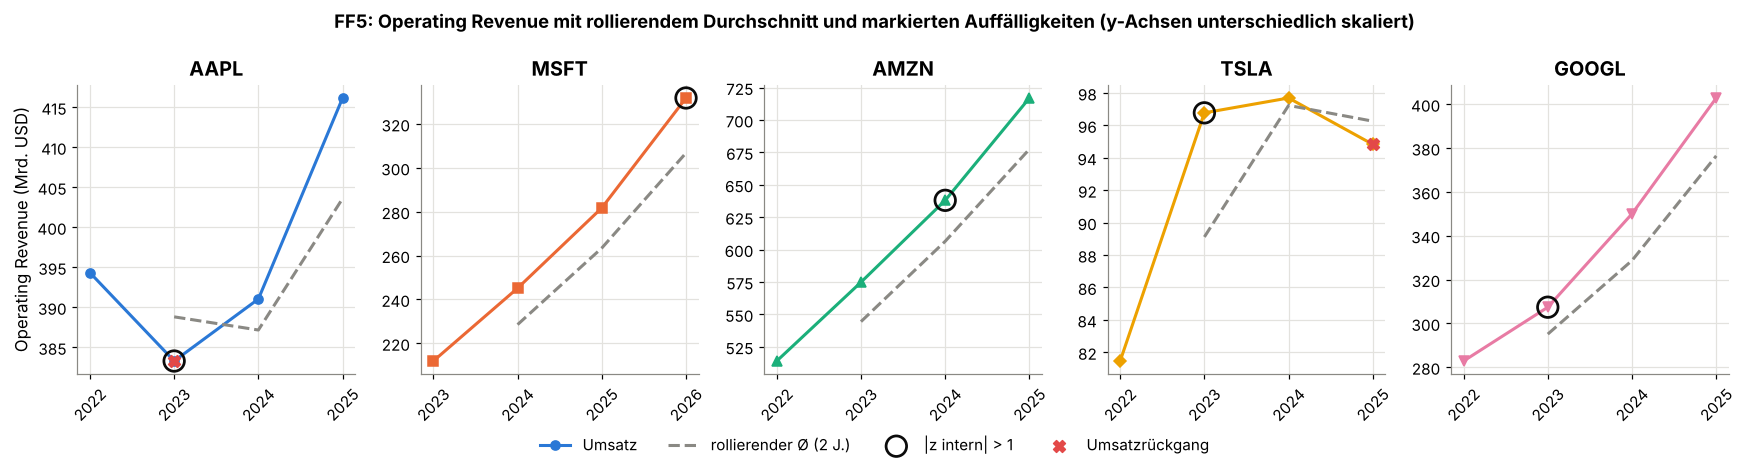

In [24]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4), sharey=False)
for ax, sym in zip(axes, UNTERNEHMEN):
    d = big5[big5["Symbol"] == sym]
    ax.plot(d["GJ"], d["Operating Revenue"] / MRD, color=FARBEN[sym], marker=MARKER[sym], markersize=6, label="Umsatz")
    ax.plot(d["GJ"], d["Rollierender Ø (2 J.)"] / MRD, color=GRAU, linestyle="--", label="rollierender Ø (2 J.)")
    intern = d[d["z intern"].abs() > 1]
    ax.scatter(intern["GJ"], intern["Operating Revenue"] / MRD, s=180, facecolor="none", edgecolor=DUNKEL,
               linewidth=1.8, zorder=4, label="|z intern| > 1")
    rueck = d[d["Wachstum"] < 0]
    ax.scatter(rueck["GJ"], rueck["Operating Revenue"] / MRD, s=60, color=ROT, marker="X", zorder=5, label="Umsatzrückgang")
    ax.set_title(sym)
    ax.set_xticks(d["GJ"])
    ax.tick_params(axis="x", labelrotation=45)
axes[0].set_ylabel("Operating Revenue (Mrd. USD)")
handles, labels = axes[0].get_legend_handles_labels()
for a in axes[1:]:
    for h, l in zip(*a.get_legend_handles_labels()):
        if l not in labels:
            handles.append(h); labels.append(l)
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("FF5: Operating Revenue mit rollierendem Durchschnitt und markierten Auffälligkeiten (y-Achsen unterschiedlich skaliert)",
             fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

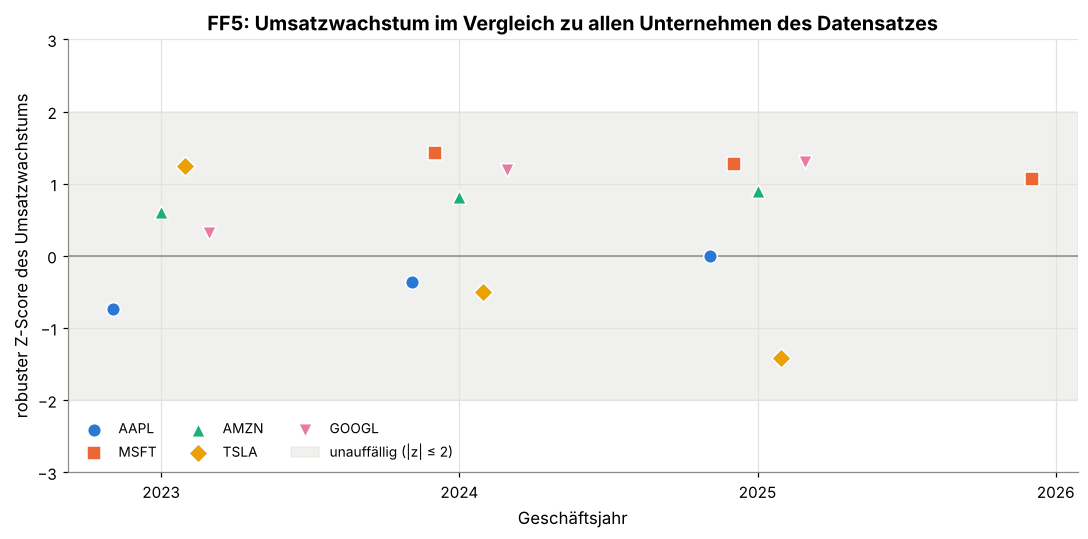

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
for i, sym in enumerate(UNTERNEHMEN):
    d = ff5[ff5["Symbol"] == sym]
    ax.scatter(d["GJ"] + (i - 2) * 0.08, d["z robust Markt"], s=80, color=FARBEN[sym], marker=MARKER[sym],
               edgecolor="white", linewidth=1, label=sym, zorder=3)
ax.axhspan(-2, 2, color="#e3e2de", alpha=0.5, zorder=0, label="unauffällig (|z| ≤ 2)")
ax.axhline(0, color=GRAU, linewidth=1)
ax.set_xticks(sorted(ff5["GJ"].unique()))
ax.set_ylim(-3, 3)
ax.set_xlabel("Geschäftsjahr")
ax.set_ylabel("robuster Z-Score des Umsatzwachstums")
ax.set_title("FF5: Umsatzwachstum im Vergleich zu allen Unternehmen des Datensatzes")
ax.legend(frameon=False, ncol=3, fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()

**Ergebnis FF5:**
- **Rollierender Durchschnitt und Wachstum:** Nur zwei Unternehmensjahre zeigen einen Umsatzrückgang: Apple 2023 (−2,8 %) und Tesla 2025 (−2,9 %). Bei Tesla fällt das Wachstum außerdem von 18,8 % (2023) auf 0,9 % (2024); der Umsatz liegt 2025 unter dem rollierenden Durchschnitt.
- **Unternehmensinterner Z-Score (|z| > 1):** markiert AAPL 2023, AMZN 2024, GOOGL 2023, MSFT 2026 und TSLA 2023. Diese Methode ist hier aber **wenig aussagekräftig**: Bei nur drei Wachstumsraten markiert sie fast automatisch das jeweils schwächste oder stärkste Jahr. AMZN 2024 wird markiert, obwohl der Umsatz um 11,0 % gewachsen ist; das ist keine Krise, sondern nur das etwas schwächere von drei sehr ähnlichen Jahren.
- **Robuster Z-Score im Marktvergleich (|z| > 2):** Kein Unternehmensjahr der fünf Unternehmen ist auffällig. Die größte Abweichung nach oben hat Microsoft 2024 (z = +1,42), nach unten Tesla 2025 (z = −1,41).

**Interpretation:** Mit den vorhandenen Daten lassen sich **keine statistisch eindeutigen Krisenjahre** nachweisen. Erkennbar sind schwächere Phasen: Apple 2023 und Tesla 2024–2025 (Stagnation, dann Rückgang). **H5 wird nicht bestätigt**; mit vier Jahren je Unternehmen sind die Zeitreihen für eine belastbare Anomalieerkennung zu kurz. Die Methode selbst ist aber übertragbar und würde mit längeren Zeitreihen (z. B. Quartalsdaten) deutlich mehr leisten.

---
## Phase 5: Ergebnispräsentation

### 5.1 Antworten auf die Forschungsfragen

| Nr. | Kernergebnis |
|---|---|
| FF1 | Der durchschnittliche Umsatz steigt im vergleichbaren Zeitraum von 314,8 (2023) über 344,4 (2024) auf 382,5 Mrd. USD (2025); das Wachstum beschleunigt sich (+9,4 % → +11,1 %). |
| FF2 | Im gemeinsamen Geschäftsjahr 2025 hat Alphabet den höchsten Nettogewinn (132,17 Mrd. USD). Nach letztem verfügbarem Abschluss liegt Microsoft (FY 2026: 133,75 Mrd. USD) knapp vorn. |
| FF3 | Bei den fünf Unternehmen kein signifikanter Zusammenhang (r = −0,22, p = 0,35). Im Gesamtdatensatz schwach negativ und signifikant (Spearman ρ = −0,215). |
| FF4 | Höchste absolute EPS-Volatilität: Microsoft (wachstumsgetrieben); höchste relative: Amazon. Sondereffekte erklären einen Teil (Amazon −26 %, Alphabet −31 % Standardabweichung nach Bereinigung), aber nicht den Großteil. |
| FF5 | Keine statistisch eindeutigen Anomalien; Umsatzrückgänge nur bei Apple 2023 und Tesla 2025. Der interne Z-Score ist bei 3 Werten je Unternehmen methodisch kaum aussagekräftig. |

### 5.2 Prüfung der Hypothesen

| Hypothese | Ergebnis |
|---|---|
| H1: Durchschnittlicher Umsatz steigt jährlich | bestätigt (für 2023–2025) |
| H2: Umsatzstärkstes Unternehmen hat den höchsten Gewinn | nicht bestätigt (Amazon nur Platz 4) |
| H3: Negative Korrelation Steuerquote – Marge | teilweise (Gesamtdatensatz schwach ja, fünf Unternehmen nein) |
| H4: Hohe EPS-Volatilität geht mit hohen Sondereffekten einher | teilweise (Amazon ja, Tesla und Microsoft nein) |
| H5: Auffällige Jahre statistisch identifizierbar | nicht bestätigt |

### 5.3 Limitationen
- **Kurze Zeitreihen:** Je Unternehmen nur 4 auswertbare Geschäftsjahre; statistische Kennzahlen (Standardabweichung, Z-Score) beruhen auf sehr wenigen Werten.
- **Fehlende Jahre als Nullen:** Die Rohdaten enthalten Platzhalter-Nullen, die erst erkannt und entfernt werden mussten (375 Unternehmensjahre im Gesamtdatensatz).
- **Unterschiedliche Geschäftsjahre:** Die Abschlüsse der fünf Unternehmen decken nicht exakt dieselben Zeiträume ab.
- **Datenqualität einzelner Variablen:** `Tax Rate For Calcs` enthält offenbar ersetzte bzw. begrenzte Werte; für Amazon fehlt `Tax Provision`, für Apple `Total Unusual Items`. Die genaue Berechnung der Kennzahlen ist im Datensatz nicht dokumentiert.
- **Kleine Vergleichsbasis 2026:** Für das Geschäftsjahr 2026 liegen erst 69 Unternehmen mit Wachstumsrate vor.
- **Nominale Werte:** keine Inflationsbereinigung.
- **Korrelation ≠ Kausalität:** FF3 zeigt einen statistischen Zusammenhang, keinen Wirkmechanismus.

### 5.4 Ausblick
- Längere Zeitreihen oder Quartalsdaten würden die Anomalieerkennung (FF5) und die Volatilitätsanalyse (FF4) deutlich belastbarer machen.
- Eine Branchenzuordnung (nicht im Datensatz enthalten) würde erlauben, die Steuer-Margen-Beziehung (FF3) je Branche zu prüfen.

---
### Technischer Hinweis zur Reproduzierbarkeit
Das Notebook ist von oben nach unten ausführbar („Restart Kernel and Run All“). Benötigt werden Python 3 und die Bibliotheken pandas, numpy, matplotlib und scipy (siehe `requirements.txt`). Die CSV-Datei muss im selben Ordner oder im Unterordner `data/` liegen.